📂 Found 502 TXT files


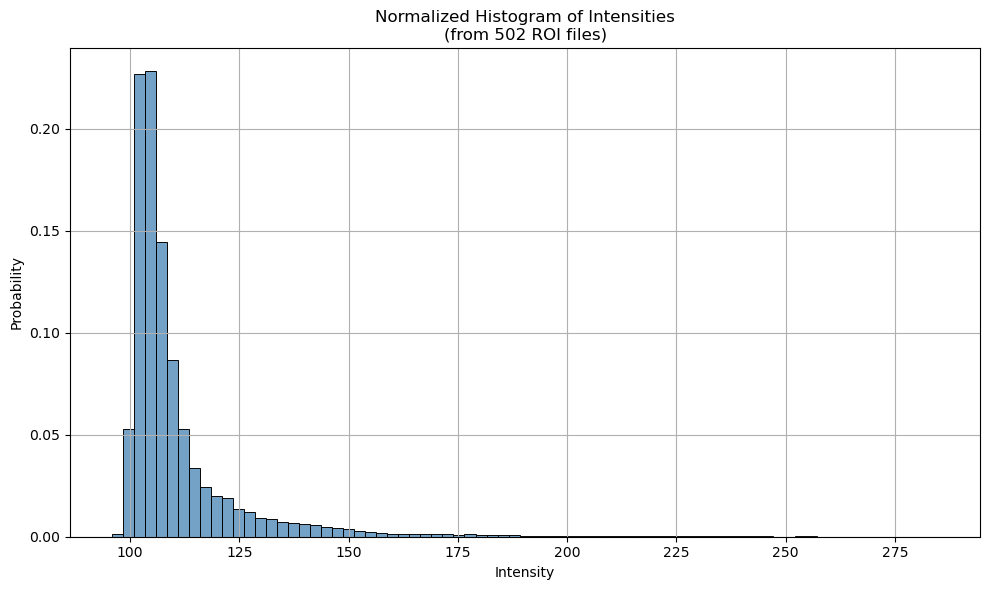

In [2]:
import pandas as pd
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt

# Path to the folder containing the TXT files
txt_dir = Path("/Volumes/T7/20250430_JFX549_Heatshock_PopZ_LowerLaser/ROI/30C_1/30C_Z-axis/generated_txt/")

# Find all .txt files
txt_files = sorted(txt_dir.glob("*.txt"))
print(f"📂 Found {len(txt_files)} TXT files")

# Load and collect all intensity values
all_intensities = []

for txt_file in txt_files:
    try:
        df = pd.read_csv(txt_file, sep="\t", header=None, names=["Frame", "Intensity"])
        all_intensities.extend(df["Intensity"].values)
    except Exception as e:
        print(f"❌ Failed to read {txt_file.name}: {e}")

# Create a DataFrame for seaborn
intensity_df = pd.DataFrame({"Intensity": all_intensities})

# Plot normalized histogram using seaborn
plt.figure(figsize=(10, 6))
sns.histplot(
    data=intensity_df,
    x="Intensity",
    bins=75,
    stat="probability",  # normalize
    kde=False,
    color="steelblue",
    edgecolor="black"
)

plt.title(f"Normalized Histogram of Intensities\n(from {len(txt_files)} ROI files)")
plt.xlabel("Intensity")
plt.ylabel("Probability")
plt.grid(True)
plt.tight_layout()
plt.show()


✔️ Fit successful:
  BG      μ=103.18, σ=2.07
  SM      μ=107.95, σ=4.37
  Cluster 2x amp=0.0022, 3x amp=2053666817512.3582


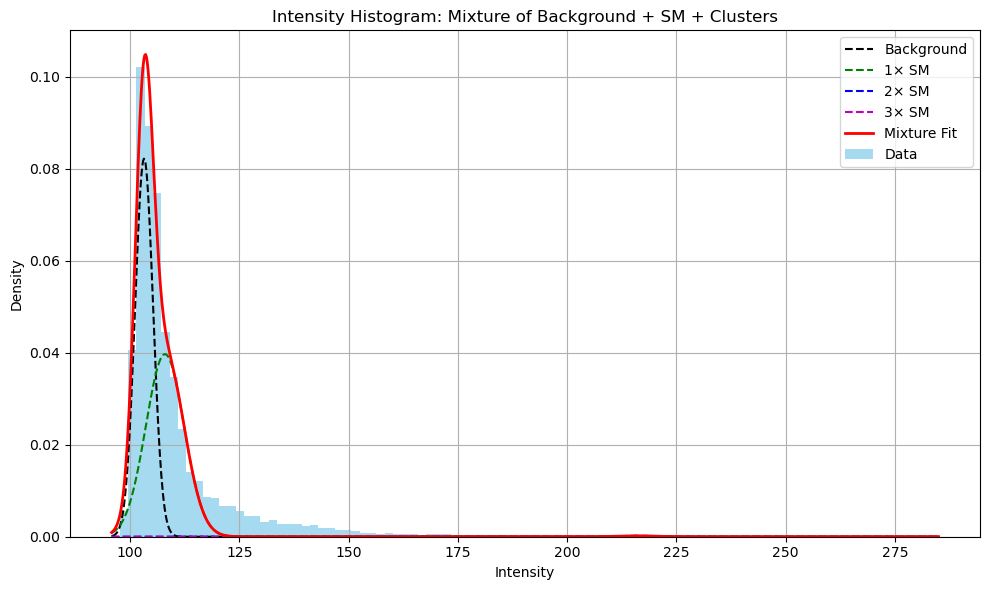

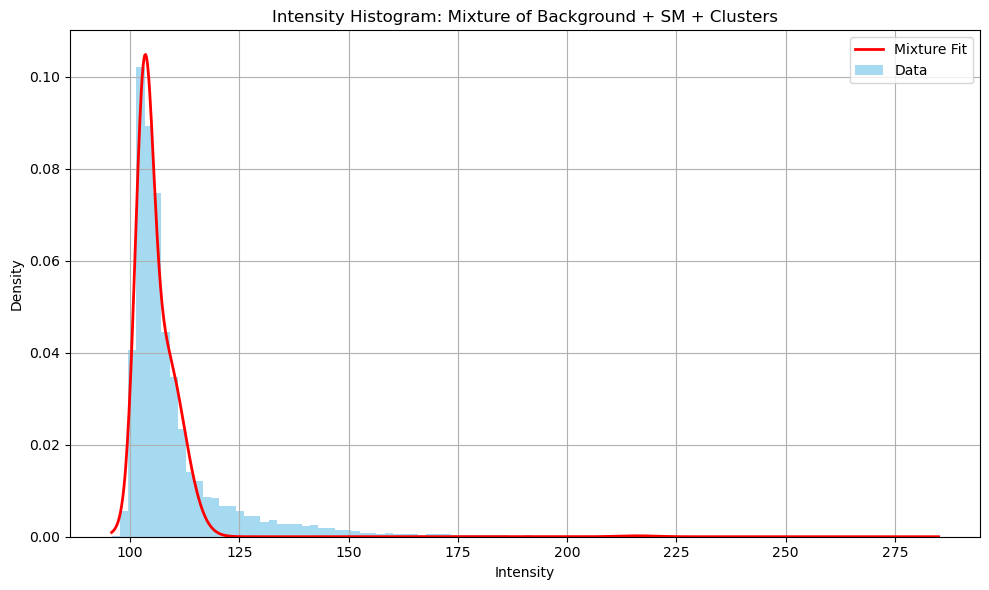

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.optimize import curve_fit
from scipy.stats import norm

# --- Load data ---
txt_dir = Path("/Volumes/T7/20250430_JFX549_Heatshock_PopZ_LowerLaser/ROI/30C_1/30C_Z-axis/generated_txt/")
txt_files = sorted(txt_dir.glob("*.txt"))

intensities = []
for txt_file in txt_files:
    try:
        df = pd.read_csv(txt_file, sep="\t", header=None, names=["Frame", "Intensity"])
        intensities.extend(df["Intensity"].values)
    except Exception as e:
        print(f"❌ Failed to read {txt_file.name}: {e}")

data = np.array(intensities)
data = data[np.isfinite(data)]

# --- Histogram ---
hist_y, bin_edges = np.histogram(data, bins=100, density=True)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

# --- Define model: mixture of 4 Gaussians (BG + SM + 2x + 3x) ---
def gaussian_mixture(x, mu_bg, sigma_bg, amp_bg, mu_sm, sigma_sm, amp_sm, amp_2, amp_3):
    g0 = amp_bg * norm.pdf(x, mu_bg, sigma_bg)                  # Background
    g1 = amp_sm * norm.pdf(x, mu_sm, sigma_sm)                  # Single molecule
    g2 = amp_2 * norm.pdf(x, 2 * mu_sm, sigma_sm)               # Dimer
    g3 = amp_3 * norm.pdf(x, 3 * mu_sm, sigma_sm)               # Trimer
    return g0 + g1 + g2 + g3

# --- Initial Guess ---
mu_bg_init = np.percentile(data, 5)
sigma_bg_init = np.std(data[data < mu_bg_init + 5])
amp_bg_init = 0.02

mu_sm_init = np.percentile(data, 25)
sigma_sm_init = np.std(data[(data > mu_sm_init - 5) & (data < mu_sm_init + 5)])
amp_sm_init = 0.02

p0 = [mu_bg_init, sigma_bg_init, amp_bg_init,
      mu_sm_init, sigma_sm_init, amp_sm_init, 0.015, 0.01]

# --- Fit ---
try:
    popt, _ = curve_fit(gaussian_mixture, bin_centers, hist_y, p0=p0, maxfev=20000)
except RuntimeError as e:
    print("❌ Fit failed:", e)
    exit()

# --- Unpack parameters ---
mu_bg, sigma_bg, amp_bg, mu_sm, sigma_sm, amp_sm, amp_2, amp_3 = popt
print(f"✔️ Fit successful:")
print(f"  BG      μ={mu_bg:.2f}, σ={sigma_bg:.2f}")
print(f"  SM      μ={mu_sm:.2f}, σ={sigma_sm:.2f}")
print(f"  Cluster 2x amp={amp_2:.4f}, 3x amp={amp_3:.4f}")

# --- Plot ---
# --- Plot ---
plt.figure(figsize=(10, 6))
sns.histplot(data, bins=100, stat="density", color="skyblue", label="Data", edgecolor=None)

x_fit = np.linspace(data.min(), data.max(), 1000)

# Individual components
g0 = amp_bg * norm.pdf(x_fit, mu_bg, sigma_bg)       # background
g1 = amp_sm * norm.pdf(x_fit, mu_sm, sigma_sm)       # single molecule
g2 = amp_2 * norm.pdf(x_fit, 2 * mu_sm, sigma_sm)     # dimer
g3 = amp_3 * norm.pdf(x_fit, 3 * mu_sm, sigma_sm)     # trimer

# Total model
y_fit = g0 + g1 + g2 + g3

# Plot each
plt.plot(x_fit, g0, 'k--', label="Background")
plt.plot(x_fit, g1, 'g--', label="1× SM")
plt.plot(x_fit, g2, 'b--', label="2× SM")
plt.plot(x_fit, g3, 'm--', label="3× SM")
plt.plot(x_fit, y_fit, 'r-', label="Mixture Fit", lw=2)

plt.title("Intensity Histogram: Mixture of Background + SM + Clusters")
plt.xlabel("Intensity")
plt.ylabel("Density")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
sns.histplot(data, bins=100, stat="density", color="skyblue", label="Data", edgecolor=None)

x_fit = np.linspace(data.min(), data.max(), 1000)
y_fit = gaussian_mixture(x_fit, *popt)

plt.plot(x_fit, y_fit, 'r-', label="Mixture Fit", lw=2)
plt.title("Intensity Histogram: Mixture of Background + SM + Clusters")
plt.xlabel("Intensity")
plt.ylabel("Density")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


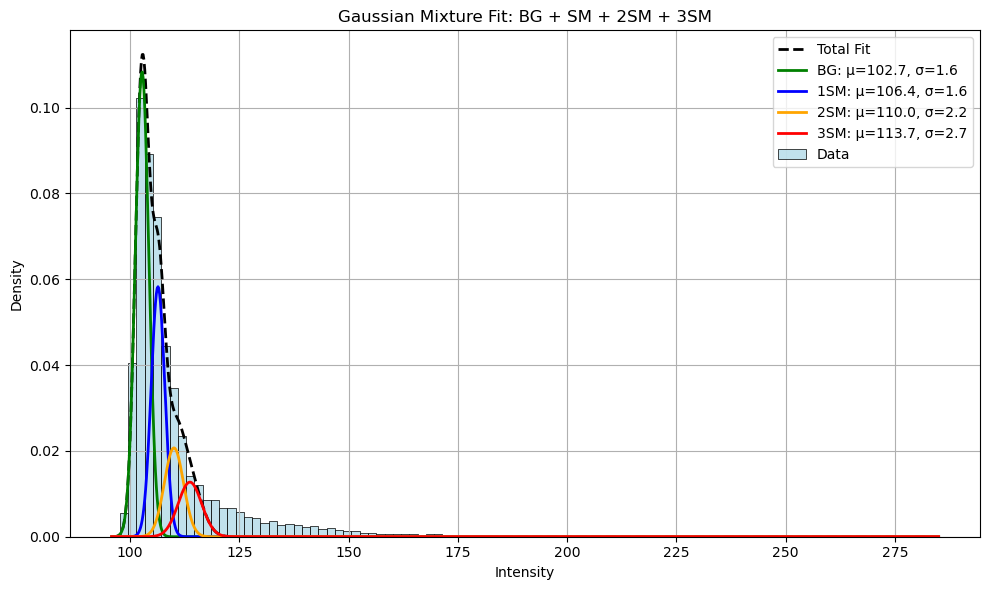

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from scipy.optimize import curve_fit
from pathlib import Path

# --- Load all .txt files ---
txt_dir = Path("/Volumes/T7/20250430_JFX549_Heatshock_PopZ_LowerLaser/ROI/30C_1/30C_Z-axis/generated_txt/")
txt_files = sorted(txt_dir.glob("*.txt"))

intensities = []
for txt_file in txt_files:
    try:
        df = pd.read_csv(txt_file, sep="\t", header=None, names=["Frame", "Intensity"])
        intensities.extend(df["Intensity"].values)
    except Exception as e:
        print(f"Failed to read {txt_file.name}: {e}")

data = np.array(intensities)
data = data[np.isfinite(data)]

# --- Histogram ---
hist_y, bin_edges = np.histogram(data, bins=200, density=True)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

# --- Initial guesses ---
mu_bg_init = np.percentile(data, 3.06)
mu_sm_init = np.percentile(data, 30)
sigma_init = np.std(data[data < mu_sm_init])
amp_init = np.max(hist_y)

def combined_gaussians(x, mu_bg, mu_sm, sigma, A_bg, A_1sm, A_2sm, A_3sm):
    G_bg = A_bg * norm.pdf(x, mu_bg, sigma)
    G_1sm = A_1sm * norm.pdf(x, mu_sm, sigma)
    G_2sm = A_2sm * norm.pdf(x, mu_bg + 2 * (mu_sm - mu_bg), np.sqrt(2) * sigma)
    G_3sm = A_3sm * norm.pdf(x, mu_bg + 3 * (mu_sm - mu_bg), np.sqrt(3) * sigma)
    return G_bg + G_1sm + G_2sm + G_3sm

# Fit
p0 = [mu_bg_init, mu_sm_init, sigma_init, amp_init, amp_init/2, amp_init/3, amp_init/4]
popt, _ = curve_fit(combined_gaussians, bin_centers, hist_y, p0=p0, maxfev=10000)
mu_bg, mu_sm, sigma, A_bg, A_1sm, A_2sm, A_3sm = popt

# Evaluate components
x_fit = np.linspace(data.min(), data.max(), 1000)
G_bg = A_bg * norm.pdf(x_fit, mu_bg, sigma)
G_1sm = A_1sm * norm.pdf(x_fit, mu_sm, sigma)
G_2sm = A_2sm * norm.pdf(x_fit, mu_bg + 2*(mu_sm - mu_bg), np.sqrt(2)*sigma)
G_3sm = A_3sm * norm.pdf(x_fit, mu_bg + 3*(mu_sm - mu_bg), np.sqrt(3)*sigma)
G_total = G_bg + G_1sm + G_2sm + G_3sm

# --- Plot ---
plt.figure(figsize=(10, 6))
sns.histplot(data, bins=100, stat="density", color="lightblue", edgecolor="black", label="Data")

plt.plot(x_fit, G_total, 'k--', lw=2, label="Total Fit")
plt.plot(x_fit, G_bg, 'g-', lw=2, label=f"BG: μ={mu_bg:.1f}, σ={sigma:.1f}")
plt.plot(x_fit, G_1sm, 'b-', lw=2, label=f"1SM: μ={mu_sm:.1f}, σ={sigma:.1f}")
plt.plot(x_fit, G_2sm, 'orange', lw=2, label=f"2SM: μ={mu_bg + 2*(mu_sm - mu_bg):.1f}, σ={np.sqrt(2)*sigma:.1f}")
plt.plot(x_fit, G_3sm, 'r-', lw=2, label=f"3SM: μ={mu_bg + 3*(mu_sm - mu_bg):.1f}, σ={np.sqrt(3)*sigma:.1f}")

plt.title("Gaussian Mixture Fit: BG + SM + 2SM + 3SM")
plt.xlabel("Intensity")
plt.ylabel("Density")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


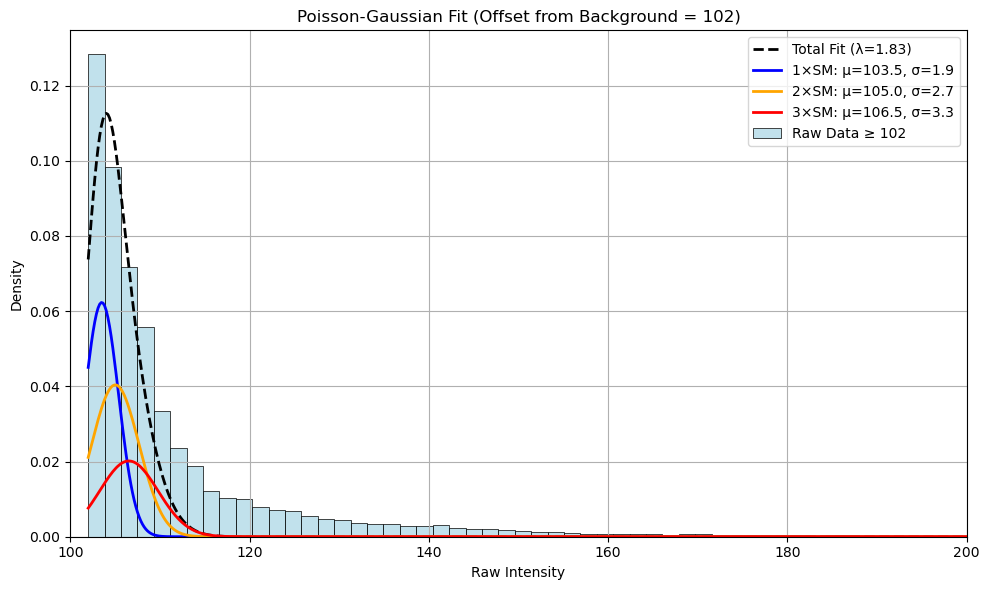

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm, poisson
from scipy.optimize import curve_fit
from pathlib import Path

# --- Load all .txt files ---
txt_dir = Path("/Volumes/T7/20250430_JFX549_Heatshock_PopZ_LowerLaser/ROI/30C_1/30C_Z-axis/generated_txt/")
txt_files = sorted(txt_dir.glob("*.txt"))

intensities = []
for txt_file in txt_files:
    try:
        df = pd.read_csv(txt_file, sep="\t", header=None, names=["Frame", "Intensity"])
        intensities.extend(df["Intensity"].values)
    except Exception as e:
        print(f"Failed to read {txt_file.name}: {e}")

data = np.array(intensities)
data = data[np.isfinite(data)]

# --- Ignore values below background threshold (102) for fitting ---
fit_data = data[data >= 102]

# --- Histogram ---
hist_y, bin_edges = np.histogram(fit_data, bins=100, density=True)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

# --- Poisson-Gaussian model with background offset ---
bg_offset = 102

def poisson_offset_model(x, mu_sm, sigma, lam):
    result = np.zeros_like(x)
    for k in range(1, 4):
        mean_k = bg_offset + k * mu_sm
        sigma_k = np.sqrt(k) * sigma
        result += poisson.pmf(k, lam) * norm.pdf(x, loc=mean_k, scale=sigma_k)
    return result

# --- Initial guess ---
mu_init = np.percentile(fit_data - bg_offset, 90)
sigma_init = np.std(fit_data - bg_offset)
lambda_init = 1.0
p0 = [mu_init, sigma_init, lambda_init]

# --- Fit ---
popt, _ = curve_fit(poisson_offset_model, bin_centers, hist_y, p0=p0, maxfev=10000)
mu_sm, sigma_sm, lam = popt

# --- Evaluate individual components ---
x_fit = np.linspace(fit_data.min(), fit_data.max(), 1000)
y_total = poisson_offset_model(x_fit, *popt)

components = []
for k in range(1, 4):
    mean_k = bg_offset + k * mu_sm
    sigma_k = np.sqrt(k) * sigma_sm
    weight = poisson.pmf(k, lam)
    comp = weight * norm.pdf(x_fit, loc=mean_k, scale=sigma_k)
    components.append((comp, mean_k, sigma_k))

# --- Plot ---
plt.figure(figsize=(10, 6))
sns.histplot(fit_data, bins=100, stat="density", color="lightblue", edgecolor="black", label="Raw Data ≥ 102")

plt.plot(x_fit, y_total, 'k--', lw=2, label=f"Total Fit (λ={lam:.2f})")

colors = ['b', 'orange', 'r']
for k, (comp, mean_k, sigma_k) in enumerate(components, start=1):
    plt.plot(x_fit, comp, color=colors[k-1], lw=2,
             label=f"{k}×SM: μ={mean_k:.1f}, σ={sigma_k:.1f}")

plt.title("Poisson-Gaussian Fit (Offset from Background = 102)")
plt.xlabel("Raw Intensity")
plt.xlim(100,200)
plt.ylabel("Density")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


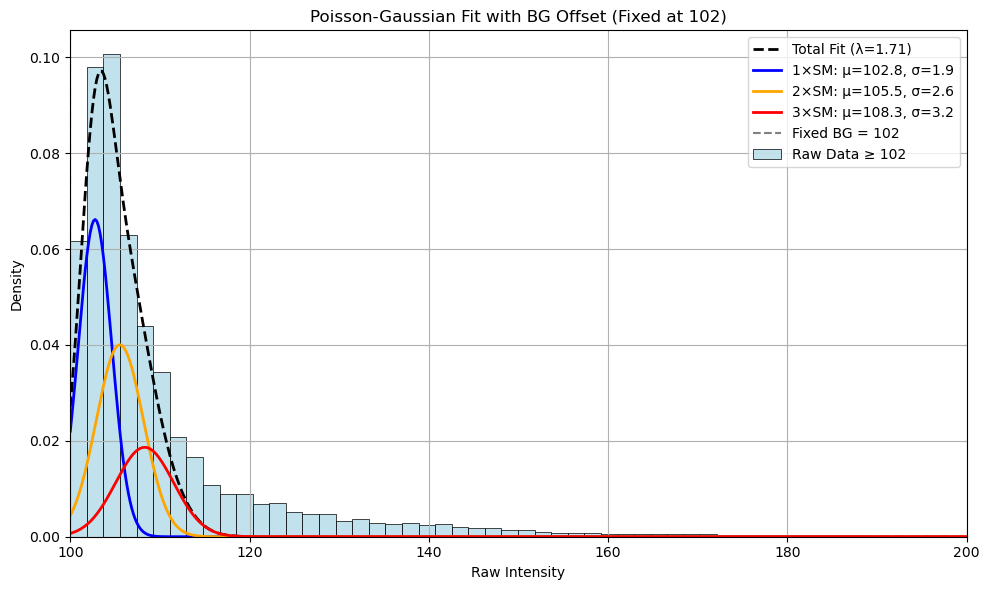

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm, poisson
from scipy.optimize import curve_fit
from pathlib import Path

# --- Load all .txt files ---
txt_dir = Path("/Volumes/T7/20250430_JFX549_Heatshock_PopZ_LowerLaser/ROI/30C_1/30C_Z-axis/generated_txt/")
txt_files = sorted(txt_dir.glob("*.txt"))

intensities = []
for txt_file in txt_files:
    try:
        df = pd.read_csv(txt_file, sep="\t", header=None, names=["Frame", "Intensity"])
        intensities.extend(df["Intensity"].values)
    except Exception as e:
        print(f"Failed to read {txt_file.name}: {e}")

data = np.array(intensities)
data = data[np.isfinite(data)]

# --- Ignore values below background threshold (102) for fitting ---
bg_offset = 100
fit_data = data[data >= bg_offset]

# --- Histogram ---
hist_y, bin_edges = np.histogram(fit_data, bins=100, density=True)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

# --- Poisson-Gaussian model with background offset fixed at 102 ---
def poisson_offset_model(x, mu_sm, sigma, lam):
    result = np.zeros_like(x)
    for k in range(1, 4):
        mean_k = bg_offset + k * mu_sm
        sigma_k = np.sqrt(k) * sigma
        result += poisson.pmf(k, lam) * norm.pdf(x, loc=mean_k, scale=sigma_k)
    return result

# --- Initial guesses (manual) ---
mu_init = 3.0          # Single molecule intensity offset from BG
sigma_init = 1.2       # Reasonable small spread
lambda_init = 1.2      # Average molecules per event
p0 = [mu_init, sigma_init, lambda_init]

# --- Fit the model ---
popt, _ = curve_fit(poisson_offset_model, bin_centers, hist_y, p0=p0, maxfev=10000)
mu_sm, sigma_sm, lam = popt

# --- Evaluate fitted components ---
x_fit = np.linspace(fit_data.min(), fit_data.max(), 1000)
y_total = poisson_offset_model(x_fit, *popt)

components = []
for k in range(1, 4):
    mean_k = bg_offset + k * mu_sm
    sigma_k = np.sqrt(k) * sigma_sm
    weight = poisson.pmf(k, lam)
    comp = weight * norm.pdf(x_fit, loc=mean_k, scale=sigma_k)
    components.append((comp, mean_k, sigma_k))

# --- Plot ---
plt.figure(figsize=(10, 6))
sns.histplot(fit_data, bins=100, stat="density", color="lightblue", edgecolor="black", label="Raw Data ≥ 102")

plt.plot(x_fit, y_total, 'k--', lw=2, label=f"Total Fit (λ={lam:.2f})")

colors = ['b', 'orange', 'r']
for k, (comp, mean_k, sigma_k) in enumerate(components, start=1):
    plt.plot(x_fit, comp, color=colors[k-1], lw=2,
             label=f"{k}×SM: μ={mean_k:.1f}, σ={sigma_k:.1f}")

plt.axvline(bg_offset, color='gray', linestyle='--', label="Fixed BG = 102")

plt.title("Poisson-Gaussian Fit with BG Offset (Fixed at 102)")
plt.xlabel("Raw Intensity")
plt.ylabel("Density")
plt.xlim(100, 200)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


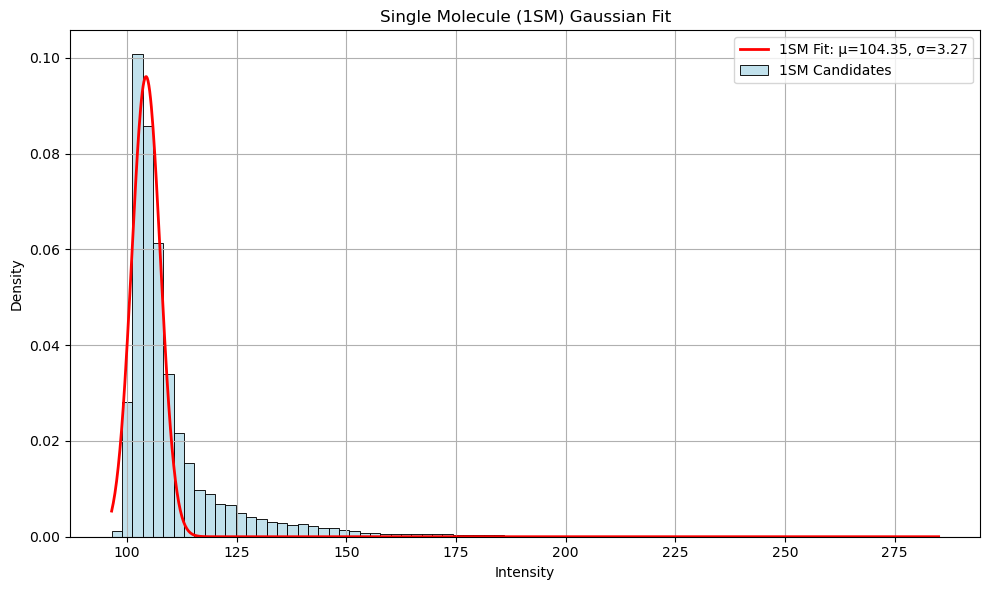

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from scipy.optimize import curve_fit
from pathlib import Path

# --- Load all .txt files ---
txt_dir = Path("/Volumes/T7/20250430_JFX549_Heatshock_PopZ_LowerLaser/ROI/30C_1/30C_Z-axis/generated_txt/")
txt_files = sorted(txt_dir.glob("*.txt"))

intensities = []
for txt_file in txt_files:
    try:
        df = pd.read_csv(txt_file, sep="\t", header=None, names=["Frame", "Intensity"])
        intensities.extend(df["Intensity"].values)
    except Exception as e:
        print(f"Failed to read {txt_file.name}: {e}")

data = np.array(intensities)
data = data[np.isfinite(data)]

# --- Filter data: only 1SM candidates (>102) and < upper threshold if desired ---
fit_data = data[data > 96]
# Optional: fit_data = fit_data[fit_data < 115]  # Use if needed to avoid 2SM tails

# --- Histogram ---
hist_y, bin_edges = np.histogram(fit_data, bins=80, density=True)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

# --- Gaussian model for 1SM only ---
def single_gaussian(x, mu, sigma, amplitude):
    return amplitude * norm.pdf(x, mu, sigma)

# --- Initial guess ---
mu_init = np.median(fit_data)
sigma_init = np.std(fit_data)
amp_init = np.max(hist_y)
p0 = [mu_init, sigma_init, amp_init]

# --- Fit ---
popt, _ = curve_fit(single_gaussian, bin_centers, hist_y, p0=p0)
mu_fit, sigma_fit, amp_fit = popt

# --- Evaluate fitted curve ---
x_fit = np.linspace(fit_data.min(), fit_data.max(), 1000)
y_fit = single_gaussian(x_fit, *popt)

# --- Plot ---
plt.figure(figsize=(10, 6))
sns.histplot(fit_data, bins=80, stat="density", color="lightblue", edgecolor="black", label="1SM Candidates")

plt.plot(x_fit, y_fit, 'r-', lw=2, label=f"1SM Fit: μ={mu_fit:.2f}, σ={sigma_fit:.2f}")

plt.title("Single Molecule (1SM) Gaussian Fit")
plt.xlabel("Intensity")
plt.ylabel("Density")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
